# Experiment 5: Data Stream Algorithms

Name: ____________________    Class / Roll No: ____________________

## Aim

Implement data stream algorithms with PySpark and Python: the Bloom Filter for membership testing and DGIM for counting 1s in a sliding window.

## Theory

Data stream algorithms process data that arrives continuously and is too large or too fast to store completely. Instead of keeping the whole stream they keep a small summary and answer queries from it. The price is a trade-off between memory, speed and accuracy.

### Bloom Filter

A Bloom Filter is a bit array of size m, all zeros at the start, plus k hash functions. To insert an item, all k hash functions give k positions and those bits are set to 1. To query an item, the same k positions are checked:

- if any bit is 0, the item is definitely not in the set
- if all bits are 1, the item is possibly in the set

So it can give false positives but never false negatives. For n inserted items the false positive rate is about (1 - e^(-kn/m)) raised to the power k, and the best number of hash functions is about (m/n) * ln 2.

### DGIM

DGIM estimates the number of 1s among the last N bits of a binary stream without storing those N bits. It keeps buckets. Each bucket stores its size (a power of 2, the number of 1s it represents) and the timestamp of its most recent 1.

- a new 1 creates a bucket of size 1
- at most 2 buckets of each size are allowed. If a third one appears, the two oldest of that size are merged into one bucket of double size
- buckets whose timestamp falls outside the window are dropped
- to answer a query, add the sizes of all buckets and count only half of the oldest bucket, because it may be partly outside the window

The error is at most 50 percent, and only about 2 * log2(N) buckets are stored instead of N bits.

## Problem Statement

A web security team has two jobs.

1. Screen a stream of URLs against a large phishing blocklist without keeping the whole list in memory (Bloom Filter).
2. Monitor server health by counting how many of the most recent N requests failed with an HTTP 5xx error (DGIM). Here 1 means the request failed and 0 means it succeeded.

Each part starts with a small example that can be checked by hand, then a larger experiment. The data is synthetic and generated in the notebook.

## Setup

Install PySpark, import the libraries and start a local SparkSession. Spark is used in Part 1 to build the Bloom Filter in parallel.

In [ ]:
!pip install pyspark -q

In [ ]:
import hashlib
import math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pyspark.sql import SparkSession

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 5)

spark = (SparkSession.builder
         .appName("Stream_Algorithms")
         .master("local[*]")
         .config("spark.sql.shuffle.partitions", "8")
         .getOrCreate())
sc = spark.sparkContext
print("PySpark initialized", spark.version)

PySpark initialized 4.0.4


## Part 1: Bloom Filter for phishing URL screening

### Hash function and filter class

The hash function is SHA-256 of the text "seed_word" turned into an integer and reduced modulo m. Using a different seed (0, 1, 2 and so on) gives k independent hash functions. The class keeps the bit array as a numpy array. `add` sets the k bits and `check` returns whether all k bits are set.

In [ ]:
def positions(word, m, k):
    out = []
    for seed in range(k):
        h = hashlib.sha256(f"{seed}_{word}".encode()).hexdigest()
        out.append(int(h, 16) % m)
    return out


class Bloom:
    def __init__(self, m, k):
        self.m = m
        self.k = k
        self.bits = np.zeros(m, dtype=np.uint8)

    def add(self, word):
        pos = positions(word, self.m, self.k)
        self.bits[pos] = 1
        return pos

    def check(self, word):
        pos = positions(word, self.m, self.k)
        return bool(self.bits[pos].all()), pos

### Small example (m = 20, k = 3)

This is small enough to follow by hand. Three domains are inserted and the bit array is printed after each insert. Then one inserted domain and two new ones are checked. A new domain is reported as absent as soon as one of its bits is 0, and it can be reported as possibly present only if all its bits happen to be 1.

In [ ]:
bf = Bloom(20, 3)
for site in ["evil-login.test", "free-gift.test", "win-prize.test"]:
    pos = bf.add(site)
    print(site, "inserted, positions", pos)
    print("bits", bf.bits.tolist())

for site in ["evil-login.test", "news-today.test", "weather.test"]:
    found, pos = bf.check(site)
    verdict = "POSSIBLY present" if found else "NOT present"
    print(site, verdict, "positions", pos)

evil-login.test inserted, positions [15, 9, 19]
bits [0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 1, 0, 0, 0, 1]
free-gift.test inserted, positions [2, 11, 15]
bits [0, 0, 1, 0, 0, 0, 0, 0, 0, 1, 0, 1, 0, 0, 0, 1, 0, 0, 0, 1]
win-prize.test inserted, positions [14, 18, 3]
bits [0, 0, 1, 1, 0, 0, 0, 0, 0, 1, 0, 1, 0, 0, 1, 1, 0, 0, 1, 1]
evil-login.test POSSIBLY present positions [15, 9, 19]
news-today.test NOT present positions [6, 15, 8]
weather.test NOT present positions [12, 2, 15]


### A false positive

With only 20 bits the filter fills up quickly. The loop below searches for a domain that was never inserted but is still reported as possibly present. That is a false positive: it happens when the bits of a new item were all set by other items. Note that the reverse never happens, so an inserted domain is always found.

In [ ]:
for i in range(10000):
    name = f"site{i}.test"
    found, pos = bf.check(name)
    if found:
        print(name, "was never inserted but is reported POSSIBLY present, positions", pos)
        break

site0.test was never inserted but is reported POSSIBLY present, positions [19, 14, 11]


### Distributed build with Spark

Now a realistic size. The blocklist has 50,000 phishing URLs. Each Spark partition builds its own local bit array with `mapPartitions`, and the partial arrays are combined with a bitwise OR in `reduce`. The OR is correct because a bit is 1 in the final filter exactly when some item set it, no matter which partition that item was in. This is the same idea as reduceByKey: combine locally first, merge second.

The filter uses 10 bits per item (m = 500,000 bits) and k = 7, close to the optimal k = 10 * ln 2 = 6.93.

In [ ]:
n = 50000
M = 500000
K = 7

blocklist = [f"phish-{i}.badsite.test/login" for i in range(n)]
safe = [f"shop-{i}.goodsite.test/home" for i in range(n)]

block_rdd = sc.parallelize(blocklist, 8)
safe_rdd = sc.parallelize(safe, 8)


def part_bits(it):
    arr = np.zeros(M, dtype=np.uint8)
    for w in it:
        arr[positions(w, M, K)] = 1
    yield arr


bits = block_rdd.mapPartitions(part_bits).reduce(np.bitwise_or)
print("bits set:", int(bits.sum()), "of", M)
print("fill ratio:", round(float(bits.mean()), 4))

bits set: 251520 of 500000
fill ratio: 0.503


### Query the filter on the whole stream

The bit array is broadcast to the workers and both URL sets are checked in parallel.

- Blocklisted URLs that are reported absent are false negatives. This must be 0.
- Safe URLs that are reported present are false positives. Their share is the false positive rate, which is compared with the formula from the theory.
- Memory is compared with storing the raw URL strings.

In [ ]:
bc = sc.broadcast(bits)
def hit(w):
    return bool(bc.value[positions(w, M, K)].all())
fn = block_rdd.filter(lambda w: not hit(w)).count()
fp = safe_rdd.filter(hit).count()
theory = (1 - math.exp(-K * n / M)) ** K

print("false negatives:", fn)
print("false positives:", fp, "of", n)
print("measured false positive rate:", round(100 * fp / n, 3), "percent")
print("theoretical rate:", round(100 * theory, 3), "percent")

raw = sum(len(w) for w in blocklist)
print("raw url text:", round(raw / 1024, 1), "KB")
print("bloom filter as bits:", round(M / 8 / 1024, 1), "KB")

false negatives: 0
false positives: 414 of 50000
measured false positive rate: 0.828 percent
theoretical rate: 0.819 percent
raw url text: 1454.0 KB
bloom filter as bits: 61.0 KB


### Effect of the filter size (Graph 1)

The same 50,000 URLs are inserted for several sizes, from 4 to 16 bits per item, with the best k for each size. Measured false positive rates are plotted against the theoretical curve on a log scale. More bits per item cuts the false positive rate sharply, but the filter needs more memory, which is the main trade-off of the Bloom Filter.

In [ ]:
rows = []
for bpi in [4, 6, 8, 10, 12, 16]:
    m = bpi * n
    k = max(1, round(bpi * math.log(2)))
    f = Bloom(m, k)
    for w in blocklist:
        f.add(w)
    fp = sum(1 for w in safe if f.check(w)[0])
    th = (1 - math.exp(-k * n / m)) ** k
    rows.append((bpi, m, k, round(100 * fp / n, 4), round(100 * th, 4)))

t1 = pd.DataFrame(rows, columns=["bits_per_item", "m", "k", "measured_pct", "theory_pct"])
print(t1)

   bits_per_item       m   k  measured_pct  theory_pct
0              4  200000   3        14.914     14.6892
1              6  300000   4         5.578      5.6057
2              8  400000   6         2.170      2.1577
3             10  500000   7         0.828      0.8194
4             12  600000   8         0.296      0.3142
5             16  800000  11         0.052      0.0459


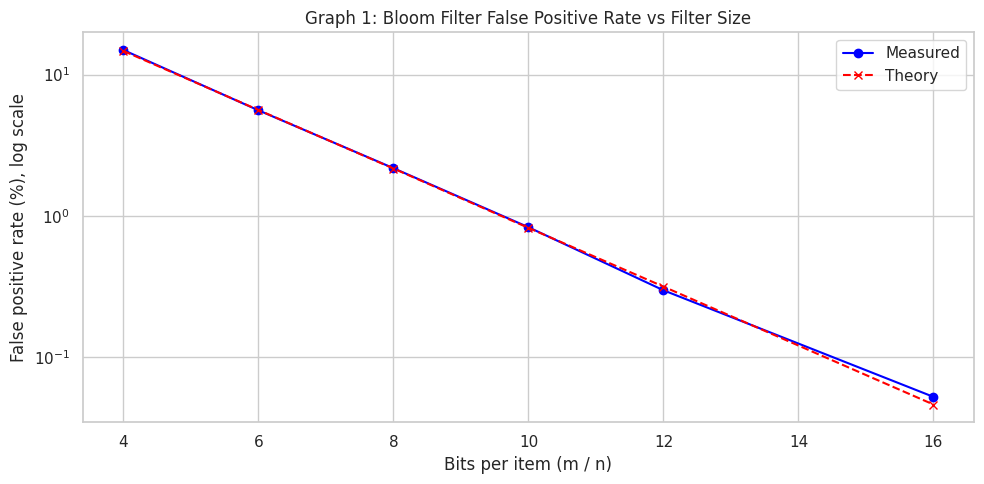

In [ ]:
fig, ax = plt.subplots()
ax.plot(t1["bits_per_item"], t1["measured_pct"], color="blue", marker="o", label="Measured")
ax.plot(t1["bits_per_item"], t1["theory_pct"], color="red", linestyle="--", marker="x", label="Theory")
ax.set_yscale("log")
ax.set_xlabel("Bits per item (m / n)")
ax.set_ylabel("False positive rate (%), log scale")
ax.set_title("Graph 1: Bloom Filter False Positive Rate vs Filter Size")
ax.legend()
plt.tight_layout()
plt.show()

## Part 2: DGIM for counting server errors in a sliding window

### DGIM class

Each bucket is a pair [size, timestamp]. The list is kept with the newest bucket first. `add` handles one request. A 0 only advances the clock and removes expired buckets. A 1 adds a bucket of size 1 and then merges upwards: whenever there are more than 2 buckets of some size, the two oldest of that size become one bucket of double size, and that may cause a merge at the next size, and so on. `estimate` adds every bucket fully except the oldest, which counts as half.

The original lab code checks merges only for sizes up to 128. Here the loop keeps doubling the size, so it also works for large windows.

In [ ]:
class DGIM:
    def __init__(self, window):
        self.window = window
        self.buckets = []
        self.time = 0

    def add(self, bit):
        self.time += 1
        if bit == 1:
            self.buckets.insert(0, [1, self.time])
            self.merge()
        self.expire()

    def merge(self):
        size = 1
        while True:
            idx = [i for i, b in enumerate(self.buckets) if b[0] == size]
            if len(idx) <= 2:
                break
            newer = idx[-2]
            older = idx[-1]
            ts = self.buckets[newer][1]
            del self.buckets[older]
            self.buckets[newer] = [size * 2, ts]
            size *= 2

    def expire(self):
        limit = self.time - self.window
        self.buckets = [b for b in self.buckets if b[1] > limit]

    def estimate(self):
        if not self.buckets:
            return 0.0
        total = sum(b[0] for b in self.buckets[:-1])
        return total + self.buckets[-1][0] / 2.0

    def show(self):
        print("size  timestamp")
        for size, ts in self.buckets:
            print(size, "   ", ts)

### Small example

A short stream of requests (1 = failed) and a window of the last 8 requests. The buckets are printed and the estimate is compared with the exact count taken from the raw stream. The estimate can be off by a little because the oldest bucket is only counted as half.

In [ ]:
stream = "1 0 0 1 1 0 1 0 1 1 1 0 0 1 1 1 0 1 1 0 1 0"
W = 8
d = DGIM(W)
for b in stream.split():
    d.add(int(b))

d.show()
exact = sum(int(b) for b in stream.split()[-W:])
est = d.estimate()
print("DGIM estimate:", est)
print("exact count:", exact)
print("absolute error:", abs(est - exact))

size  timestamp
1     21
2     19
2     16
DGIM estimate: 4.0
exact count: 5
absolute error: 1.0


### Larger experiment: bursts of errors

A stream of 150,000 requests with a normal error rate of 5 percent and three bursts of 6,000 requests at 60 percent (for example a bad deployment). DGIM runs with several window sizes. Every 100 requests, once the window is full, the estimate is compared with the exact count taken from a running sum. Only windows with at least one error are used for the percentage error.

In [ ]:
rng = np.random.default_rng(7)
T = 150000
p = np.full(T, 0.05)
for s in (30000, 75000, 120000):
    p[s:s + 6000] = 0.6
stream = (rng.random(T) < p).astype(int)
cs = np.cumsum(stream)

def exact_count(t, W):
    return int(cs[t] - (cs[t - W] if t >= W else 0))

def run(W, step=100):
    d = DGIM(W)
    out = []
    for t in range(T):
        d.add(int(stream[t]))
        if t % step == step - 1 and t >= W - 1:
            out.append((t, exact_count(t, W), d.estimate(), len(d.buckets)))
    return out
res = {}
summ = []
for W in [100, 500, 1000, 5000, 10000, 50000]:
    r = pd.DataFrame(run(W), columns=["t", "actual", "est", "nb"])
    res[W] = r
    v = r[r["actual"] > 0]
    err = 100 * (v["est"] - v["actual"]).abs() / v["actual"]
    summ.append((W, round(err.mean(), 2), round(err.max(), 2), round(r["nb"].mean(), 1), int(r["nb"].max())))

t2 = pd.DataFrame(summ, columns=["window", "mean_err_pct", "max_err_pct", "avg_buckets", "max_buckets"])
print(t2)

   window  mean_err_pct  max_err_pct  avg_buckets  max_buckets
0     100         15.42        50.00          3.8           11
1     500         11.10        36.84          7.1           15
2    1000         10.55        36.59          8.7           17
3    5000         11.27        37.58         12.3           20
4   10000         11.50        40.65         13.9           20
5   50000          8.55        33.10         18.3           23


### Estimate vs actual count (Graph 2)

For a window of 1,000 requests the DGIM estimate follows the exact count through the three error bursts. The two lines stay close, and the small gap comes from counting the oldest bucket as half.

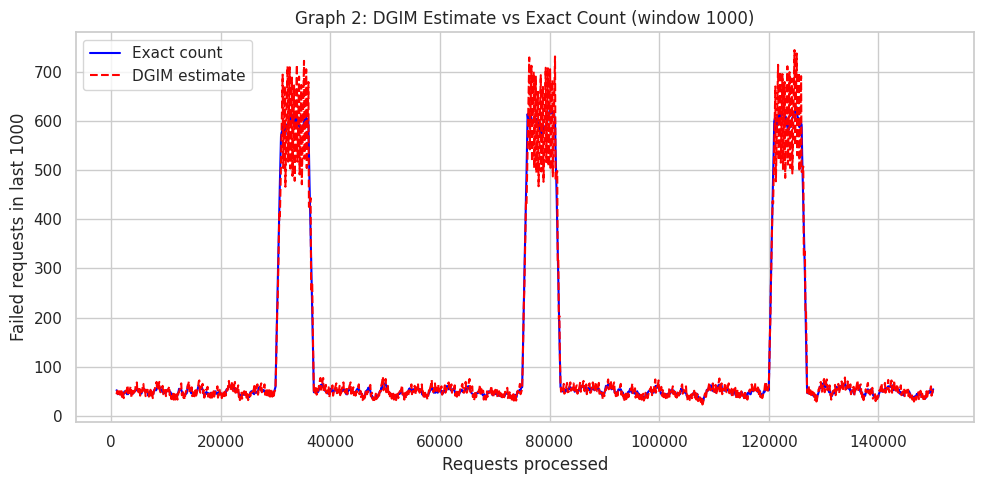

In [ ]:
r = res[1000]
fig, ax = plt.subplots()
ax.plot(r["t"], r["actual"], color="blue", label="Exact count")
ax.plot(r["t"], r["est"], color="red", linestyle="--", label="DGIM estimate")
ax.set_xlabel("Requests processed")
ax.set_ylabel("Failed requests in last 1000")
ax.set_title("Graph 2: DGIM Estimate vs Exact Count (window 1000)")
ax.legend()
plt.tight_layout()
plt.show()

### Memory used (Graph 3)

Storing the window exactly needs W bits. DGIM needs only a handful of buckets, and that number grows with log2 of W and not with W. Both axes are on a log scale, so the exact storage is a straight rising line and the DGIM bucket count is almost flat.

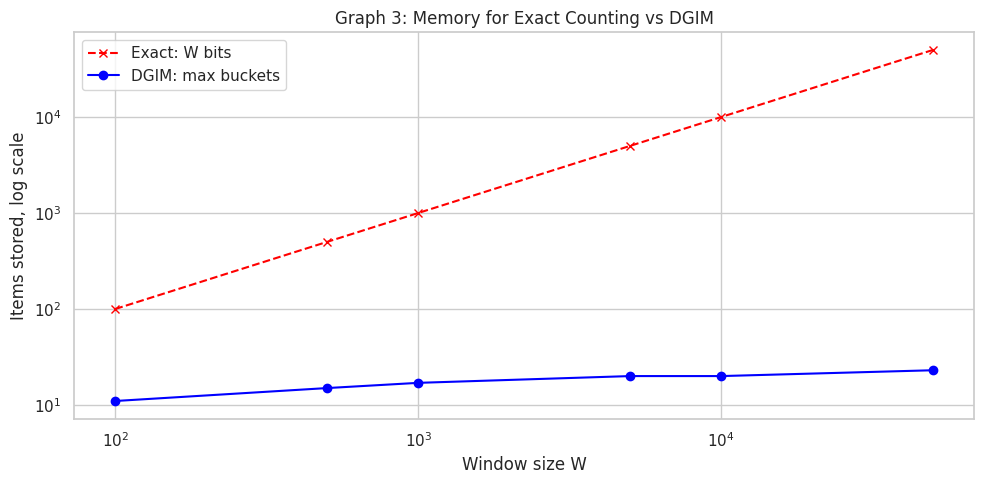

In [ ]:
fig, ax = plt.subplots()
ax.plot(t2["window"], t2["window"], color="red", linestyle="--", marker="x", label="Exact: W bits")
ax.plot(t2["window"], t2["max_buckets"], color="blue", marker="o", label="DGIM: max buckets")
ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlabel("Window size W")
ax.set_ylabel("Items stored, log scale")
ax.set_title("Graph 3: Memory for Exact Counting vs DGIM")
ax.legend()
plt.tight_layout()
plt.show()

## Interactive mode (optional)

The lab version of this experiment reads its input from the keyboard. The functions below do the same for the small Bloom Filter and for DGIM. They are switched off by default so that Run all does not stop and wait for typing. Set the flag to True and run the cell to try your own input.

In [ ]:
def bloom_menu(m=20, k=3):
    f = Bloom(m, k)
    while True:
        print("\nBLOOM FILTER")
        print("1. Insert")
        print("2. Membership check")
        print("3. Exit")
        c = input("Enter your choice: ").strip()
        if c == "1":
            while True:
                w = input("Enter a word to insert (or type no to stop): ").strip()
                if w.lower() == "no":
                    break
                pos = f.add(w)
                print(w, "inserted, positions", pos)
                print("bits", f.bits.tolist())
        elif c == "2":
            w = input("Enter a word to check: ").strip()
            found, pos = f.check(w)
            print(w, "is POSSIBLY present" if found else "is NOT present", "positions", pos)
        elif c == "3":
            break
        else:
            print("Invalid choice, select 1, 2 or 3")


def dgim_prompt():
    s = input("Enter request stream (0 ok, 1 failed), separated by spaces: ").strip()
    W = int(input("Enter sliding window size: "))
    d = DGIM(W)
    bits = [int(b) for b in s.split()]
    for b in bits:
        d.add(b)
    d.show()
    est = d.estimate()
    exact = sum(bits[-W:])
    print("DGIM estimate:", est)
    print("exact count:", exact)
    print("absolute error:", abs(est - exact))
    if exact != 0:
        print("percentage error:", round(100 * abs(est - exact) / exact, 2))


RUN_INTERACTIVE = False
if RUN_INTERACTIVE:
    bloom_menu()
    dgim_prompt()

## Observations

Read these against your own output. The data is synthetic, so exact numbers can differ slightly on your run.

- Small Bloom Filter: an inserted domain is always reported as possibly present, and a domain is reported absent as soon as one of its bits is 0. With only 20 bits the filter fills up fast, and the search finds a domain that was never inserted but is still reported as possibly present. That is a false positive.
- Distributed build: the OR of the partial bit arrays from the Spark partitions gives the same filter as inserting everything in one place. About half of the 500,000 bits are set, which is what the optimal number of hash functions aims for.
- Query results: there are 0 false negatives, and the measured false positive rate (about 0.83 percent) is very close to the theoretical value (about 0.82 percent). The filter needs about 61 KB, against about 1.4 MB for the raw URL text.
- Graph 1: the false positive rate drops from about 15 percent at 4 bits per item to about 0.05 percent at 16 bits per item, and the measured points sit on the theory curve. Each extra bit per item costs memory but cuts the error by a constant factor.
- Small DGIM example: the estimate is 4 and the exact count is 5. The 1 unit gap comes from the oldest bucket (size 2), which is counted as half because it might be partly outside the window.
- DGIM experiment: the mean error is about 8 to 15 percent for every window size and the maximum stays below the 50 percent bound. The error percentage is larger for small windows because a count of a few errors is easily off by one.
- Graph 2: the estimate follows the exact count and rises and falls with the three error bursts, so DGIM is good enough for detecting a bad deployment.
- Graph 3: the number of buckets grows very slowly (about 11 for a window of 100 and about 23 for a window of 50,000), while exact counting needs W bits. This is the memory saving that DGIM gives.

## Conclusion

This experiment implemented two data stream algorithms. The Bloom Filter answered membership queries for 50,000 blocklisted URLs in a small bit array, with no false negatives and a false positive rate that matched the formula, and Spark built it in parallel by OR-ing the partial bit arrays. DGIM estimated the number of failed requests in a sliding window from only a few buckets and followed the exact count closely, including during error bursts. In both cases a compact summary replaced the full data, and the price was a small, controllable error: the false positive rate falls as the filter gets more bits, and the DGIM error is bounded by the half-counted oldest bucket.